# 9. Diseño de evaluación

El protocolo fija MASE como métrica primaria y MAE, RMSE y sMAPE como complementarias. La diferencia relativa de interés es δ = 3 %, con α = 0,05 y potencia objetivo 0,80. La unidad de evaluación es el origen diario que produce 24 etiquetas.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


## Formulación y entradas

Para un origen diario $o$, la salida es $\mathbf{y}_o=(y_o,\ldots,y_{o+23})$. El pronóstico directo se expresa como

$$\widehat{\mathbf{y}}_o=f_\theta(\mathbf{X}_{o-168:o-1},\mathbf{K}_{o:o+23}),$$

donde $\mathbf{X}$ contiene observaciones pasadas alineadas por disponibilidad y $\mathbf{K}$ contiene calendario conocido. La configuración base utiliza demanda y calendario; clima, hidrología y titulares fundamentan extensiones posteriores.

La unidad de evaluación es el origen diario, con 24 errores relacionados. Las semillas describen variación del ajuste y no hacen independientes los errores de un mismo día.

La selección utiliza cuatro pliegues anuales: 2018, 2019, 2020 y 2021. El entrenamiento se amplía cronológicamente. El último 10 % de los orígenes anteriores a cada año se reserva para parada temprana. El diagrama utiliza únicamente desarrollo 2000–2021; las métricas de prueba 2022–2025 se presentan en el capítulo 10. El denominador de MASE permanece fijo en la referencia histórica 2000–2017: permite comparar valores en la misma escala, aunque los periodos pueden tener distinto nivel y dificultad de pronóstico.

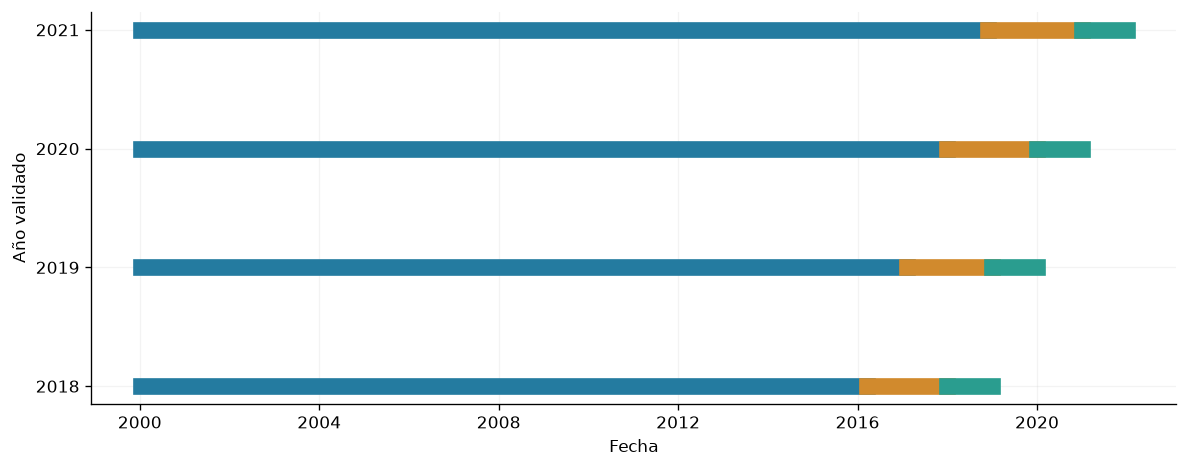

,año,entrenamiento,parada_interna,validacion
0,2018,5911,657,365
1,2019,6240,693,365
2,2020,6568,730,366
3,2021,6898,766,365


In [2]:
H=24; L=168; indice=panel.index; candidatos=np.arange(L,len(panel)-H+1); candidatos=candidatos[indice[candidatos].hour==0]; filas=[]; fig,ax=plt.subplots()
for fila,anio in enumerate([2018,2019,2020,2021]):
    inicio=pd.Timestamp(f'{anio}-01-01',tz='America/Bogota'); fin=pd.Timestamp(f'{anio+1}-01-01',tz='America/Bogota'); pre=candidatos[indice[candidatos]+pd.Timedelta(hours=H-1)<inicio]; n_es=max(1,round(.1*len(pre))); es=pre[-n_es:]; tr=pre[indice[pre]+pd.Timedelta(hours=H-1)<indice[es[0]]]; val=candidatos[(indice[candidatos]>=inicio)&(indice[candidatos]+pd.Timedelta(hours=H-1)<fin)]; assert indice[tr[-1]]+pd.Timedelta(hours=23)<indice[es[0]]; assert indice[es[-1]]+pd.Timedelta(hours=23)<indice[val[0]]
    filas.append({'año':anio,'entrenamiento':len(tr),'parada_interna':len(es),'validacion':len(val)})
    for posiciones,color in [(tr,'#247ba0'),(es,'#d18a2d'),(val,'#2a9d8f')]: ax.plot([indice[posiciones[0]],indice[posiciones[-1]]],[fila,fila],color=color,lw=10)
ax.set(yticks=range(4),yticklabels=range(2018,2022),xlabel='Fecha',ylabel='Año validado'); fig.tight_layout(); display(fig); plt.close(fig); display(pd.DataFrame(filas))

Cada bloque verde corresponde a un año posterior a la historia de ajuste; el tramo naranja reserva parada temprana dentro de esa historia. Los conteos verifican separación de etiquetas entre ajuste, parada y validación externa. El año 2020 conserva su propio pliegue, permitiendo identificar el comportamiento de ese régimen.

### Pipeline por origen

El panel aplica los rezagos de disponibilidad. Para un origen en la posición `p`, la historia contiene filas `p−168` a `p−1`, mientras el calendario del horizonte utiliza `p` a `p+23`. La demanda futura sólo se emplea como etiqueta. La media de demanda de la ventana es una escala conocida al origen.

In [3]:
p=int(val[0]); historia=panel.iloc[p-L:p]; horizonte=panel.iloc[p:p+H]; X_pasado=historia[['x_demanda_real_kwh']].to_numpy(); calendario=[c for c in panel.columns if c.startswith('cal_') and pd.api.types.is_numeric_dtype(panel[c])]; K_futuro=horizonte[calendario].to_numpy(); Y=horizonte['y_demanda_real_kwh'].to_numpy(); nivel=float(X_pasado.mean()); X_nivel=X_pasado/nivel; Y_nivel=Y/nivel; assert historia.index.max()<horizonte.index.min(); assert nivel>0; display(pd.DataFrame([{'forma_historia':str(X_nivel.shape),'forma_calendario':str(K_futuro.shape),'forma_etiquetas':str(Y_nivel.shape),'nivel_kWh':nivel}]))
filas_ajuste=panel.iloc[int(tr.min())-L:int(tr.max())]; assert filas_ajuste.index.max()<indice[es[0]]; media_cal=filas_ajuste[calendario].mean(); escala_cal=filas_ajuste[calendario].std().replace(0,1); K_estandar=(horizonte[calendario]-media_cal)/escala_cal; escala_mase=float(panel.loc[panel.index<'2018-01-01','y_demanda_real_kwh'].diff(168).abs().dropna().mean()); display(pd.Series({'escala_MASE_semanal_kWh':escala_mase,'margen_relativo':.03,'alfa':.05,'potencia_objetivo':.8}))

,forma_historia,forma_calendario,forma_etiquetas,nivel_kWh
0,"(168, 1)","(24, 23)","(24,)",7.502089e+06


escala_MASE_semanal_kWh    215617.903616
margen_relativo                 0.030000
alfa                            0.050000
potencia_objetivo               0.800000
dtype: float64

**Decisión.** Separar ajuste, parada interna, validación externa y prueba.

**Impacto.** Homogeneiza la comparación y preserva el orden temporal.

**Riesgo.** La prueba retrospectiva y las versiones revisadas de las fuentes limitan la independencia histórica; la inferencia debe seguir su preregistro.

## Métricas y comparación

Para $N$ orígenes y $H=24$:

$$\operatorname{MAE}=\frac{1}{NH}\sum_o\sum_{h=0}^{H-1}|y_{o+h}-\widehat y_{o+h}|,$$

$$\operatorname{RMSE}=\sqrt{\frac{1}{NH}\sum_o\sum_{h=0}^{H-1}(y_{o+h}-\widehat y_{o+h})^2},\qquad
\operatorname{MASE}=\frac{\operatorname{MAE}}{q_{168}},$$

$$q_{168}=\frac{1}{T-168}\sum_{t=168}^{T-1}|y_t-y_{t-168}|.$$

La escala $q_{168}$ procede del bloque de referencia histórico 2000–2017, anterior a los años externos de validación. MASE es la métrica primaria; MAE se interpreta en kWh por intervalo y RMSE acentúa errores grandes. sMAPE promedia $200|y-\widehat y|/(|y|+|\widehat y|)$, con contribución cero cuando ambos son cero. Un MASE inferior a 1 compara con la escala histórica de entrenamiento; la comparación con el ingenuo en validación requiere calcular también su error sobre los mismos orígenes.

Persistencia y referencias diaria y semanal deben utilizar la misma disponibilidad que los modelos. El reporte desagrega por hora del horizonte, año y tipo de día, además de media, desviación e intervalos entre semillas. El margen relativo de interés es 3 %; α = 0,05 y potencia objetivo 0,80 son parámetros del diseño inferencial.

## Búsqueda y prevención de fuga

La selección utiliza confirmación de validación con dos semillas y cuatro años externos. Los escaladores de características se ajustan exclusivamente con las filas de optimización de cada pliegue; parada interna y evaluación externa permanecen separadas. MLP y ARX ajustan además su estandarización tabular sobre el mismo tramo de optimización. El nivel histórico de cada ventana se calcula antes del origen. La escala fija de MASE de 2000–2017 es un denominador de evaluación y no una entrada del optimizador.

El análisis temporal emplea bloques de 14 días, con siete y 28 como sensibilidad; 10.000 réplicas e índices apareados. DM–HLN utiliza covarianza HAC de 14 rezagos diarios. Las familias de contrastes y sus ajustes de multiplicidad se especifican en el capítulo de evaluación. Los resultados son exploratorios y se distinguen de una confirmación independiente.

## Unidad de evaluación, bloques y comparaciones

Para dos métodos $A$ y $B$, se define una pérdida por origen

$$\ell_{m,o}=\frac{1}{24q_{168}}\sum_{h=0}^{23}|y_{o+h}-\widehat y_{m,o+h}|,\qquad
d_o=\ell_{A,o}-\ell_{B,o}.$$

El apareamiento exige los mismos días y horizontes; las 24 horas no se tratan como réplicas independientes. El intervalo temporal se estima con bloques contiguos de días para conservar dependencia serial. La variación entre semillas se reporta separadamente: no se concatenan como si multiplicaran el número de días observados.

Se comparan las tres redes entre sí, cada red frente a ARX y cada familia frente a los ingenuos diario y semanal. Holm se aplica separadamente por familia de hipótesis; los horizontes se ajustan conjuntamente dentro de cada familia. Las diferencias, intervalos, tamaños de efecto y valores p se reportan junto con sus supuestos. TOST examina θ_AB=(μ_A−μ_B)/μ_MLP con un único margen relativo de ±3 %, sin inferir equivalencia por ausencia de significación.

El dimensionamiento usa diferencias de MASE entre semillas piloto, agregadas primero sobre los cuatro años externos. El resultado se interpreta como planificación aproximada condicionada al piloto; no convierte las fechas compartidas en réplicas independientes.

## Implementación de remuestreo temporal

La función siguiente implementa índices de bootstrap circular por bloques. Su ejemplo utiliza un índice artificial, no errores ni resultados de modelos. El análisis secundario temporal utiliza 14 días como bloque principal y 7 y 28 como sensibilidad, con índices de remuestreo apareados entre modelos.

In [4]:
def indices_bootstrap_bloques(n,longitud,rng):
    if not 1<=longitud<=n:
        raise ValueError('La longitud debe estar entre 1 y n.')
    comienzos=rng.integers(0,n,size=int(np.ceil(n/longitud)))
    return ((comienzos[:,None]+np.arange(longitud))%n).ravel()[:n]

rng=np.random.default_rng(11037)
ejemplo=indices_bootstrap_bloques(60,14,rng)
assert ejemplo.shape==(60,) and ejemplo.min()>=0 and ejemplo.max()<60


En el análisis temporal, los mismos índices se aplican conjuntamente a las pérdidas de ambos métodos. El remuestreo debe respetar los bloques de evaluación y cualquier cambio del procedimiento de reajuste; no debe cruzarlos indiscriminadamente.

## Ejecución y alcance estadístico

Las configuraciones se seleccionan por confirmación de validación con dos semillas y cuatro años; el piloto evalúa cinco semillas por pliegue y la prueba cinco realizaciones por familia. El preprocesamiento se ajusta sólo al tramo de optimización de cada pliegue. El máximo es 30 épocas en filtro y 60 en confirmación, piloto y final; la parada temprana aplica mínimo diez épocas y paciencia seis, restaurando el mínimo absoluto.

MASE es la métrica primaria, δ relativo es 3 %, α=0,05 y la potencia objetivo de diseño es 0,80. El tamaño ejecutado de cinco semillas no demuestra esa potencia. Los intervalos por inicialización son condicionales al mismo conjunto de fechas; el remuestreo temporal conserva días completos y bloques de siete, 14 y 28 días. Los contrastes tienen alcance exploratorio.

## Registro del diseño y cierre de selección

| Familias seleccionadas | Fecha del commit del plan | Cierre de selección y piloto | Finalización de evaluación |
|---|---|---|---|
| MLP, ARX y CNN1D | [2026-11-08T11:39:32-05:00](https://github.com/Fabian-11037/Prediccion-Demanda-Electrica/commit/a840e3694dca546b0f41a540355bc48d0cf956cc) | 2026-11-08T12:00:08.061476-05:00 | 2026-11-08T12:02:06.321373-05:00 |
| LSTM | [2026-11-08T12:15:50-05:00](https://github.com/Fabian-11037/Prediccion-Demanda-Electrica/commit/7ca4644bcfc98cac7c95383cc98eb8144651b240) | 2026-11-08T12:30:24.221509-05:00 | 2026-11-08T12:32:15.538888-05:00 |

Las fechas se conservan con el huso de los registros. Los planes preceden al cierre de selección de cada grupo, pero el plan de LSTM de las 12:15:50 se registró después de finalizar la evaluación de MLP, ARX y CNN1D a las 12:02:06. Sus resultados de prueba ya estaban disponibles; este orden impide asumir una planificación conjunta independiente de esa información. La cronología acredita disponibilidad, sin demostrar por sí sola qué resultados se usaron para cada decisión. Además, el bloque 2022–2025 había sido consultado en evaluaciones anteriores: no constituye prueba independiente ni prospectiva. Cerrar una configuración antes de su propia evaluación no elimina esa exposición. No se cumple el orden piloto → dimensionamiento → número de semillas de §4.1: el dimensionamiento presentado no determinó las cinco realizaciones. Se conserva como limitación metodológica, junto con el presupuesto desigual y la potencia insuficiente para el margen del 3 %.

## Identidad del conjunto de prueba

La huella visible en el capítulo de evaluación identifica 1.461 orígenes UTC y sus 24 etiquetas, mediante serialización canónica int64/float64 little-endian. Las etiquetas coinciden en las 20 realizaciones seleccionadas. La huella de contenido permite verificar identidad; por sí sola no acredita la fecha en que se congeló el conjunto. [Especificación y SHA-256](_static/resultados/huella_prueba.json).